# EMQA_L5_cal_by_trade

**Calendar-year forwards by trade date versus realised spot**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_cal_by_trade/EMQA_L5_cal_by_trade.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Each calendar-year baseload product on OPCOM, by auction date, and the realised mean spot of that year.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# OPCOM PCCB-LE-flex auction results: one row per traded session, price converted to EUR with the ECB EUR/RON fixing
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()


def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return 'other'
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return 'M'
    if n == 3 and s.month in (1, 4, 7, 10):
        return 'Q'
    if n == 6 and s.month in (1, 7):
        return 'H'
    if n == 12 and s.month == 1:
        return 'Y'
    return 'other'


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 +
                FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
# baseload ('banda LD') products with a standard delivery period
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()


def vwap(df):
    """Volume-weighted average price, EUR/MWh."""
    return float(np.average(df['price_eur_mwh'], weights=df['mwh'])) if len(df) else np.nan


def realised(s, e, col='RO'):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


print(len(FW), 'traded auctions from', d(FW['auction_date'].min()), 'to', d(FW['auction_date'].max()),
      '|', len(BASE), 'baseload auctions with a standard delivery period')

2298 traded auctions from 2020-05-12 to 2026-10-28 | 1361 baseload auctions with a standard delivery period


In [5]:
# calendar-year baseload products
CY = BASE[BASE['kind'] == 'Y'].copy()
CY['dy'] = CY['delivery_start'].dt.year

In [6]:
calt = {}
for y, g in CY.groupby('dy'):
    if len(g) < 5:          # products with fewer than five auctions are not shown
        continue
    calt[y] = {'n': len(g), 'vwap': vwap(g), 'realised': realised(pd.Timestamp(f'{y}-01-01'), pd.Timestamp(f'{y}-12-31'))}
    show(f'Cal-{y}: auctions', len(g), f'cal.{y}.n', 'd')
    show(f'Cal-{y}: VWAP, EUR/MWh', calt[y]['vwap'], f'cal.{y}.vwap', '.1f')
    if not np.isnan(calt[y]['realised']):
        show(f'Cal-{y}: realised mean spot, EUR/MWh', calt[y]['realised'], f'cal.{y}.realised', '.1f')

Cal-2021: auctions                                                  163   [cal.2021.n]
Cal-2021: VWAP, EUR/MWh                                            51.3   [cal.2021.vwap]
Cal-2021: realised mean spot, EUR/MWh                             111.4   [cal.2021.realised]
Cal-2022: auctions                                                  150   [cal.2022.n]
Cal-2022: VWAP, EUR/MWh                                            77.4   [cal.2022.vwap]
Cal-2022: realised mean spot, EUR/MWh                             265.3   [cal.2022.realised]
Cal-2023: auctions                                                  123   [cal.2023.n]
Cal-2023: VWAP, EUR/MWh                                           172.5   [cal.2023.vwap]
Cal-2023: realised mean spot, EUR/MWh                             103.7   [cal.2023.realised]
Cal-2024: auctions                                                   26   [cal.2024.n]
Cal-2024: VWAP, EUR/MWh                                           141.3   [cal.2024.vwap]
Cal-2024: 

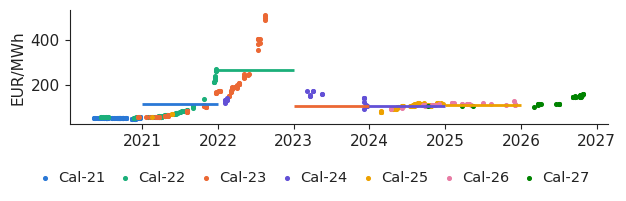

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 2.05))
cols_ = [PAL['RO'], PAL['HU'], PAL['DE_LU'], PAL['c7'], PAL['BG'], PAL['c5'], PAL['c6']]
for i, y in enumerate([y for y in sorted(calt) if y <= END.year + 1]):
    g = CY[CY['dy'] == y]
    ax.scatter(g['auction_date'], g['price_eur_mwh'], s=7, color=cols_[i % len(cols_)], label=f'Cal-{str(y)[2:]}')
    if not np.isnan(calt[y]['realised']) and y <= END.year - 1:
        ax.hlines(calt[y]['realised'], pd.Timestamp(f'{y}-01-01'), pd.Timestamp(f'{y}-12-31'), color=cols_[i % len(cols_)], lw=2.0)
ax.set_ylabel('EUR/MWh')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_compact(fig, ncol=7)
save_chart(fig, 'cal_by_trade')